# PPKS 05: Implementacija DFT-a i analiza spektra signala

***

## Frekvencijska domena

Frekvencijska domena je domena u kojoj nezavisna varijabla nema interpretaciju vremena (kao u vremenskoj domeni), nego frekvencije. Dakle, umjesto promatranja vrijednosti amplitude signala u pojedinom vremenskom trenutku, prelazimo na promatranje amplituda i faza pojedinih sinusoidalnih komponenti od kojih se signal sastoji. Prostor frekvencija u kojem promatramo neki signal nazivamo __frekvencijski spektar__.

Diskretni signal iz vremenske u frekvencijsku domenu prelazi __Diskretnom Fourierovom transformacijom (DFT)__ koja za signal u vremenu $x[n]$ s $N$ diskretnih uzoraka glasi:

$$
\begin{equation}
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi k\frac{n}{N}}
\end{equation}
$$

$X[k]$ je kompleksni broj koji predstavlja amplitudu i fazu $k$-te spektralne komponente, odnosno sinusoide čija je frekvencija $f_k$ određena cijelim brojem $k$:
$$
\begin{equation}
f_k=\frac{k}{N}f_s \; ,k \in \mathbb{Z}
\end{equation}
$$

gdje je $f_s$ frekvencija uzorkovanja signala $x[n]$.

Kroz sljedeće primjere pokazat ćemo kako smo došli do tog izraza, kako signal izgleda u frekvencijskoj domeni i zašto baš tako, koliko ima spektralnih komponenti i za što sve signal u tom obliku možemo koristiti. Primjer signala u vremenskoj i frekvencijskoj domeni je dan u nastavku. U programskom kodu Fourierova transformacija izvedena je pomoću funkcije __fft__  biblioteke _NumPy_. Brza Fourierova transformacija (engl. _Fast Fourier Transform_, FFT) smatra se jednim od najvažnijih algoritama 20. stoljeća. Kasnije će biti opisano kako točno radi. Za sad je važno znati da pozivanjem funkcije __fft__ prebacujemo signal iz vremenske u frekvencijsku domenu što je prikazano na sljedećem primjeru.



<IPython.core.display.Javascript object>


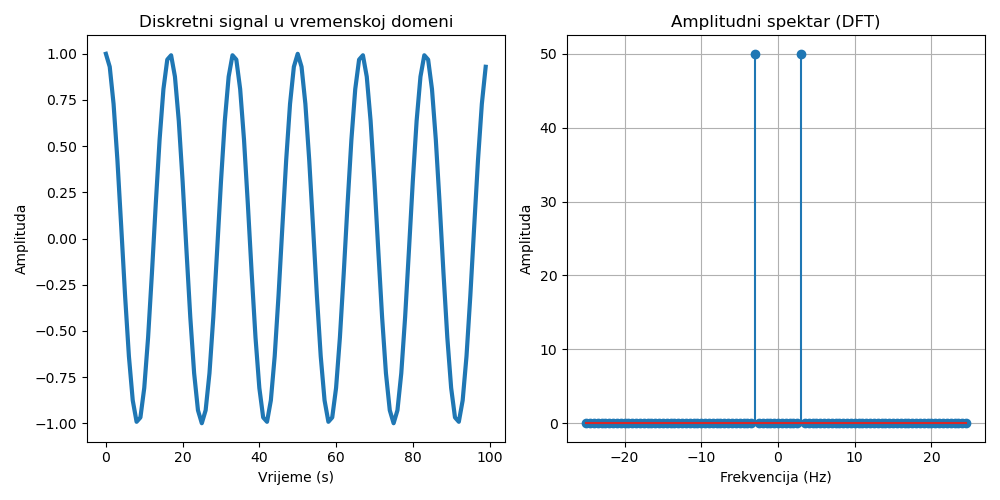

In [1]:
%matplotlib notebook

import numpy as np
import matplotlib.pyplot as plt

N = 100  # Broj uzoraka
fs = 50  # Frekvencija uzorkovanja (Hz)
n = np.arange(N) 

f0 = 3  #Hz
x = np.cos(2 * np.pi * f0 * n/fs) 

# DFT pomoću FFT
X = np.fft.fft(x)
freqs = np.fft.fftfreq(N, 1/fs)  # Frekvencijska os u frekvencijskoj domeni

X_magnitude = np.abs(X)


plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(n, x, label='Ulazni signal frekvencije 3 Hz', linewidth=3)
plt.xlabel('Vrijeme (s)')
plt.ylabel('Amplituda')
plt.title('Diskretni signal u vremenskoj domeni')

plt.subplot(1, 2, 2)
plt.stem(freqs, X_magnitude, use_line_collection=True)
plt.xlabel('Frekvencija (Hz)')
plt.ylabel('Amplituda')
plt.title('Amplitudni spektar (DFT)')
plt.grid()

plt.tight_layout()
plt.show()



### Zašto?

Ideja ovog poglavlja je objasniti zašto signal $x[n]=\cos (2\pi f_0 n)$ ima upravo takav prikaz u frekvencijskoj domeni, odnosno zašto se pojavljuju dvije spektralne komponente, zašto se nalaze na tim pozicijama i zašto je takav način promatranja signala uopće koristan. 

Za početak, odgovorimo na posljednje 'zašto'. Dok u vremenskoj domeni pratimo kako se amplituda signala mijenja kroz vrijeme, frekvencijska domena nam omogućuje da vidimo od kojih se frekvencijskih komponenti signal sastoji. Takav pogled je koristan jer mnogi komunikacijski sustavi obrađuju signale na određenim frekvencijama. __Filtriranjem__ možemo ukloniti neželjene dijelove spektra kao što su visoke ili niske frekvencije ili izdvojiti samo određeni frekvencijski opseg koji nas zanima. Iz frekvencijskog prikaza lako je odrediti __dominantne frekvencije__ u signalu što je važno u obradi slike i zvuka, detekciji anomalija (kvarovi strojeva) i medicinskoj dijagnostici.

Posebno važna primjena frekvencijske domene je u __kompresiji podataka__ gdje se koristi činjenica da signal često nema jednako važan sadržaj na svim frekvencijama. Kod kompresije slike JPEG-om, slika se najprije transformira iz prostorne domene u frekvencijsku pomoću diskretne kosinusne transformacije (DCT). Time se slika razlaže na skup frekvencijskih komponenti koje opisuju spore promjene (niskofrekventni sadržaj) i brze promjene (visokofrekventni detalji). Ljudsko oko je osjetljivije na niske frekvencije, odnosno na grube strukture i oblike, dok je manje osjetljivo na fine detalje. Zbog toga se visokofrekventne komponente mogu kvantizirati grublje ili čak zanemariti. Time se postiže značajno smanjenje količine podataka uz relativno mali gubitak vizualne kvalitete.

Sličan princip koristi se i kod kompresije zvuka. U MP3 formatu audio signal se prebacuje u frekvencijsku domenu i analizira u vremensko-frekvencijskim blokovima. Pri tome se koristi model ljudskog sluha koji određuje koje frekvencijske komponente čovjek zapravo može čuti. Komponente koje su maskirane jačim signalima na susjednim frekvencijama ili su izvan područja osjetljivosti sluha mogu se ukloniti ili zapisati s manjom preciznošću. Na taj način postiže se velika kompresija uz zadržavanje subjektivnog dojma kvalitete zvuka.

***

## Sličnost signala

Joseph Fourier, francuski matematičar i fizičar po kojem je Fourierova analiza dobila ime, pokazao je da se signal može prikazati kao zbroj sinusoidalnih komponenti različitih frekvencija. U tom smislu, signal možemo promatrati kao kombinaciju jednostavnih __referentnih signala__ koje ćemo označiti s $y_k$. Svaki od tih signala ima jedinstvenu frekvenciju $f_k$ i u diskretnom vremenu može se zapisati kao:

$$
\begin{equation}
y_k[n]=\cos\left(2\pi f_k \frac{n}{f_s} \right)
\end{equation}
$$

gdje je $f_s$ frekvencija uzorkovanja.

Ideja je uspoređivati ulazni signal $x[n]$ s referentnim signalima $y_k[n]$ kako bismo vidjeli od kojih se sve frekvencija sastoji. Ako izračunamo sličnost signala $x[n]$ sa svakom od tih sinusoida ($y_k$), znat ćemo koliko svaka od njih doprinosi ulaznom signalu. 
U pojednostavljenom smislu, sličnost između dva diskretna signala jednakih duljina ($N$) možemo izračunati njihovim skalarnim produktom:

$S(x, y)=\sum_{n=0}^{N-1}x[n]y[n]$

Kad su vrijednosti na uzorcima istog predznaka, umnožak je pozitivan, a u suprotnom je negativan. Kao rezultat dobivamo jedan broj koji prikazuje koliko su ta dva signala slična. Kratki podsjetnik: ranije smo pričali o korelaciji kao operaciji koja mjeri sličnost signala, ali je njezin izlaz novi signal, dok ovdje želimo jedan broj.

U nastavku je dan primjer u kojem signal $x[n]=\cos(2\pi \cdot3 \frac{n}{f_s})$  uspoređujemo s referentnim signalima $y_k$ u kojima $k$ ide od $0$ do $N$. Pitanje je zašto samo do $N$ i koje sve frekvencije uopće želimo provjeravati. A odgovorit ćemo i zašto se kod signala koji ima jednu frekvenciju, u frekvencijskoj domeni (prikazanoj po varijabli $k$) pojavljuju dvije frekvencijske komponente.



<IPython.core.display.Javascript object>


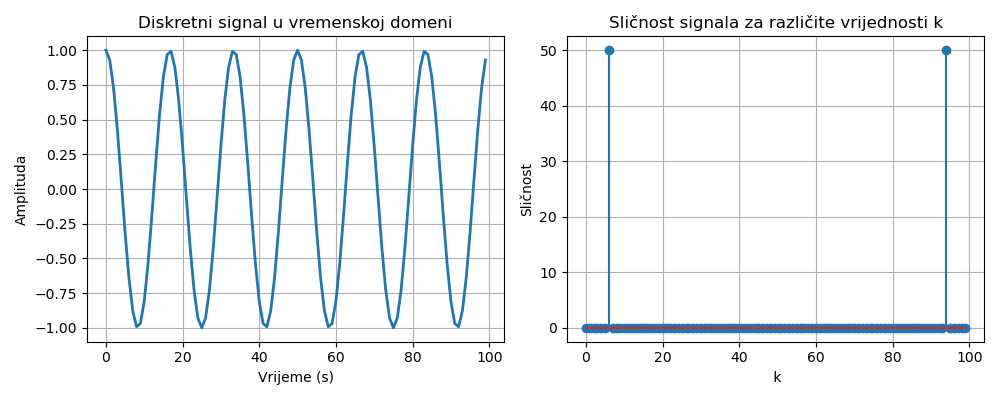

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def similarity(x):

    N = len(x)
    similarities = np.zeros(N)
    
    for k in range(N):
        reference_signal = np.cos(2 * np.pi * k * np.arange(N) / N)
        similarities[k] = np.dot(x, reference_signal)
    
    return similarities

N = 100  # Broj uzoraka
fs = 50  # Frekvencija uzorkovanja (Hz)
n = np.arange(N)   

f1 = 3  # (Hz)
x = np.cos(2 * np.pi * f1 * n /fs)

similarities = similarity(x)
frequencies = np.arange(N)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(n, x, linewidth=2)
plt.xlabel('Vrijeme (s)')
plt.ylabel('Amplituda')
plt.title('Diskretni signal u vremenskoj domeni')
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(frequencies, similarities)
plt.xlabel(' k')
plt.ylabel('Sličnost')
plt.title('Sličnost signala za različite vrijednosti k')
plt.grid()

plt.tight_layout()
plt.show()


Prvo, pretpostavit ćemo da $x[n]$ zadovoljava __Nyquist-Shannonov teorem uzorkovanja__, odnosno da je najviša frekvencija u tom signalu niža od polovice frekvencije uzorkovanja: $f_{max}\le \frac{f_s}{2}$

To nam odgovara na pitanje u kojem frekvencijskom području će se nalaziti frekvencije za koje želimo provjeriti čine li ulazni signal $x[n]$:
$f_k \in [-\frac{f_s}{2}, \frac{f_s}{2}]$. 
S tim smo ograničili koje frekvencije nam dolaze u obzir, ali i dalje je među njima beskonačno mnogo mogućih frekvencija. Zato radimo sljedeću pretpostavku.

Budući da taj signal želimo prikazati sinusoidama koje su periodične, pretpostavit ćemo i da se naš ulazni signal također ponaša periodično s periodom $N$ pa vrijedi:
$x[n]=x[n+N]=x[n+2N]...$

Dakle, signal koji nije periodičan, već je konačan i ima $N$ uzoraka ćemo prozvati periodičnim i reći da se ponavlja svakih $N$ uzoraka.
Problem je što će referentni signal koji u periodu $N$ ne napravi cijeli ciklus, za svaki sljedeći period će biti pomaknut u fazi pa će davati drugu vrijednost sličnosti. To nas ograničava na sinusoide koje u periodu $N$ rade cijeli broj ciklusa pa ih prikazujemo na sljedeći način:
$$
f_k=\frac{k}{N}f_s
$$
gdje je $k$ cijeli broj.

Do toga smo došli tako što smo za $x[n]$ rekli da se ponaša periodično: $x[n]=x[n+N]$. Ako za $x[n]$ uzmemo bilo koji signal predstavljen sad s:

$x[n]=e^{j2\pi f\frac{n}{fs}}$

to znači da je:

$x[n+N]=e^{j2\pi f\frac{n+N}{fs}}$

$x[n+N]=e^{j2\pi f\frac{n}{fs}} \cdot e^{j2\pi f\frac{N}{fs}}$

Ako želimo izjednačiti $x[n]=x[n+N]$, $e^{j2\pi f\frac{N}{fs}}$ mora biti jednak $1$, odnosno $f\frac{N}{fs}$ mora biti cijeli broj. Taj cijeli broj označit ćemo s $k$:
$$
k=f\frac{N}{fs}
$$

pa za frekvenciju referentnog signala pišemo $f_k=k\frac{f_s}{N}$. Odnosno, referentni signal je:

$$
\begin{equation}
y_k[n]=\cos\left(2\pi k \frac{n}{N} \right)
\end{equation}
$$



***

Koliko ima takvih frekvencija?

Ako uzmemo slučaj $k=N+1$:

$y_{N+1}[n]=\cos\left(2\pi k \frac{N+1}{N} \right)$

$y_{N+1}[n]=\cos\left(2\pi k \frac{N}{N} +  2\pi k \frac{n}{N}\right)$

Prvi dio kosinusa možemo zanemariti jer množi $2 \pi$ s cijelim brojem $k$, a drugi dio nam je zapravo jednak kao da smo koristili $k=1$. To znači da su frekvencije referentnih signala $f_{N+1}$ i $f_{1}$ aliasi. Isto se može pokazati za svaki $k > N$ pa zaključujemo da u frekvencijskoj domeni imamo ukupno $N$ mogućih frekvencija u području između $-\frac{f_s}{2}$ i $ \frac{f_s}{2}$.

Ali pogledajmo opet $x[n]$ s obzirom na Nyquist-Shannonov teorem uzorkovanja:

$
f_{max}\le \frac{f_s}{2}
$

To znači da najviša frekvencija do koje gledamo $f_k$ mora biti:

$f_k\le \frac{f_s}{2}$

$k\cdot \frac{f_s}{N}\le \frac{f_s}{2}$

To znači da je $k\le \frac{N}{2}$. Ali maloprije smo zaključili da je $k \in \left[0, N-1 \right]$. Pitanje je što se događa s frekvencijama za $k \in \left[\frac{N}{2},N-1\right]$? Ta je frekvencija očito izvan ograničenja pa mora imati alias na $f_k-f_s$ (Napomena: alias frekvencije za neku frekvenciju $f$ su na pozicijama $...f-2f_s$, $f-f_s$, $f+f_s$, $f+2f_s...$) Pogledajmo gdje se ta alias frekvencija nalazi:

$f_{k2}=f_k-f_s=k\cdot \frac{f_s}{N}-f_s$

$f_{k2}=\frac{k\cdot f_s-n\cdot f_s}{N}$

$f_{k2}=\frac{(k-N)\cdot f_s}{N}$

Budući da znamo da je $k \in \left[0, N-1 \right]$, $k$ će uvijek biti manji od $N$ pa će i ta frekvencija $f_{k2}$ biti manja od $0$. Dakle radi se o negativnoj frekvenciji. 

Odnosno, sve frekvencije u kojima je $k < \frac{N}{2}$ su pozitivne, a za $k \in \left[\frac{N}{2},N-1\right]$ su negativne. Važno je napomenuti da u ovom primjeru koristimo kosinus koji je **realni signal**. Realni signal je onaj čije su vrijednosti realni brojevi (nema imaginarnog dijela), što znači da takav signal možemo direktno mjeriti u stvarnosti (npr. zvuk ili napon).

***


### Negativne frekvencije

Što znači da je frekvencija negativna? Svaki signal možemo zamisliti kao rotaciju vektora u kompleksnoj ravnini:
- pozitivna frekvencija odgovara rotaciji suprotno od smjera kazaljke na satu (što je standardna matematička orijentacija)
- negativna frekvencija odgovara rotaciji u smjeru kazaljke na satu

Odnosno, predznak frekvencije u kompleksnoj ravnini određuje smjer rotacije promatranog vektora.

Treba napomenuti da negativne frekvencije nisu dodatne frekvencije, već su povezane s pozitivnima. Točnije, **za realne signale** vrijedi da se svaka frekvencijska komponenta pojavljuje u paru: jedna pozitivna i jedna negativna. 

To možemo vidjeti na primjeru kosinusnog signala:

$x[n] = \cos\left(2\pi f_0 \frac{n}{f_s}\right)$

Iako se radi o realnom signalu, on se može zapisati kao zbroj dviju kompleksnih eksponencijalnih komponenti:

$x[n] = \frac{1}{2} e^{j 2\pi f_0 \frac{n}{f_s}} + \frac{1}{2} e^{-j 2\pi f_0 \frac{n}{f_s}}$

Ove dvije rotacije su kompleksno konjugirane i međusobno se "poništavaju" u imaginarnom dijelu pa ostaje samo realni kosinus. Zato kosinus u frekvencijskoj domeni ima dvije spektralne komponente, a ne jednu. Obje komponente imaju jednaku amplitudu i međusobno su kompleksno konjugirane. 

Kada promatramo spektar po $k$:
- prva polovica spektra ($ k < \frac{N}{2} $) predstavlja pozitivne frekvencije
- druga polovica ($ k \ge \frac{N}{2} $) predstavlja negativne frekvencije (aliasirane iznad Nyquista)

**Za realne signale** obje polovice nose istu informaciju zbog konjugirane simetrije pa je u praksi dovoljno analizirati samo prvih $\frac{N}{2}$ koeficijenata.



***


Pogledajmo još jednom prošli primjer. $k$ ide od $0$ do $N-1$, a vrijednosti različite od $0$ imamo samo u točkama $k=6$ i $k=94$. Za prvu, uz frekvenciju uzorkovanja $f_s=50 Hz$ i broj uzoraka $N=100$ dobivamo $f_6=3 Hz$, a za drugu $f_{94}=-3 Hz$. Zato kad iscrtavamo na negativnu stranu spektra (lijevu) stavljamo frekvencije dobivene s  $k \in \left[ \frac{N}{2}, N-1 \right]$, a na pozitivnu (desnu) frekvencije dobivene s $k \in \left[ 0, \frac{N}{2} \right>$. 






***

## Računanje spektra pomoću sličnosti signala

Problem kod računanja frekvencijskog spektra signala $x[n]$ pomoću sličnosti signala može se vidjeti na sljedećem primjeru. Kreirali smo signal $x[n]=\cos\left(2 \pi \cdot \frac{3}{N} \cdot n\right)$ tako da bude identičan kao jedna od referentnih funkcija s kojom ga uspoređujemo (za $k=3$). Budući da je u tom primjeru $f_s=50 \text{ Hz}$ i $N=100$, frekvencija tog signala je $f_3=1,5 \text{ Hz}.$ Na iscrtanim grafovima se može vidjeti da je za svaki drugi referentni signal sličnost $0$ jer krivulja na desnoj strani, koja prikazuje rezultate umnožaka po uzorcima, za svaki drugi $k$ titra jednako oko $0$ pa je zbroj tih umnožaka nula. Jedini referentni signal za koji to nije tako dobiven je s $k=3$. 

To se može i matematički pokazati:

$$
\begin{equation}
S_k=\sum_{n=0}^{N-1}x[n]y[n]
\end{equation}
$$
$$
\begin{equation}
S_k=\sum_{n=0}^{N-1}\cos \left(2 \pi \cdot \frac{3}{N} \cdot n \right)\cdot \cos \left(2 \pi \cdot \frac{k}{N} \cdot n \right)
\end{equation}
$$

Za umnožak kosinusa znamo da vrijedi $\cos(\alpha)\cdot\cos(\beta)=\frac{1}{2}\left[\cos(\alpha+\beta)+\cos(\alpha-\beta)\right]$ pa možemo zapisati:
$$
\begin{equation}
S_k=\sum_{n=0}^{N-1}\frac{1}{2} \left[ \cos\left(2 \pi \cdot\frac{3+k}{N} \cdot n\right)+ \cos \left(2 \pi\cdot \frac{3-k}{N} \cdot n\right) \right]
\end{equation}
$$

Sad imamo dva slučaja:

 1. ako je $k\ne 3$ oba kosinusa iz sume titraju oko $0$ pa je i ukupna suma jednaka $0$. Općenito za sinusoide koje u $N$ uzoraka naprave cijeli broj perioda vrijedi da je njihova suma $\sum_{n=0}^{N-1}\cos \left( 2 \pi \frac{mn}{N} \right )$ za $m \ne 0$ jednaka nuli jer im se pozitivne i negativne vrijednosti međusobno poništavaju. 
 2. ako je $k=3$, u prvom se kosinusu ($\cos \left(2 \pi \cdot\frac{3+k}{N} \cdot n \right)$ ta suma također istitra u $0$, ali u drugom kosinusu imamo sljedeće:
 $$
\begin{equation}
S_3=\sum_{n=0}^{N-1}\frac{1}{2} \left[ \cos \left(2 \pi\cdot \frac{3-3}{N} \cdot n\right) \right]
\end{equation}
$$
  $$
\begin{equation}
S_3=\sum_{n=0}^{N-1}\frac{1}{2} \cos(0) = \frac{N}{2}
\end{equation}
$$

Možemo primijetiti da je za $k=3$ sličnost jednaka $50$, što je točno $\frac{N}{2}$.



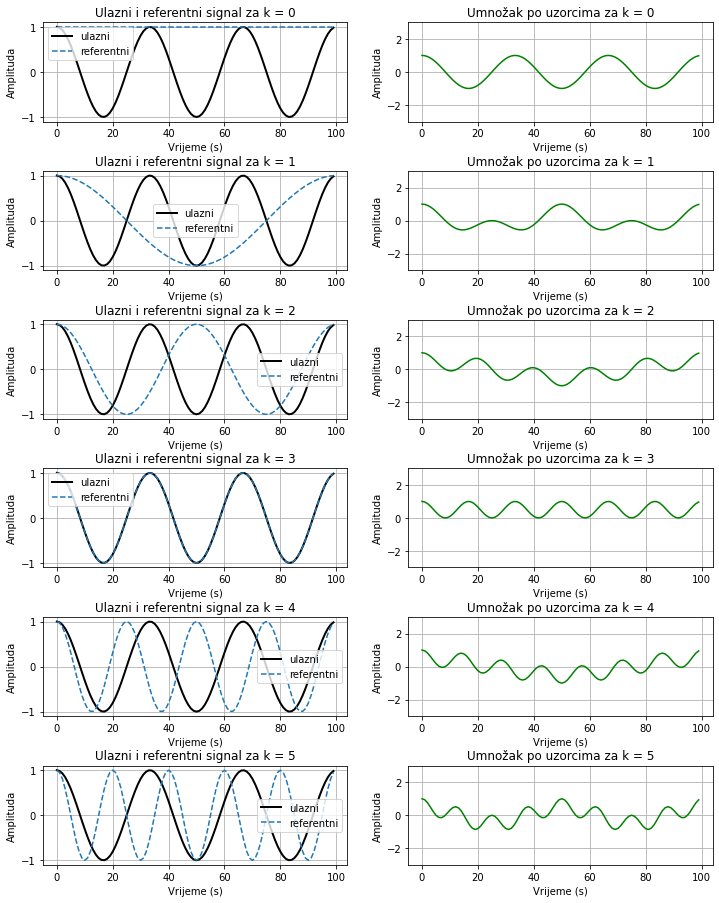

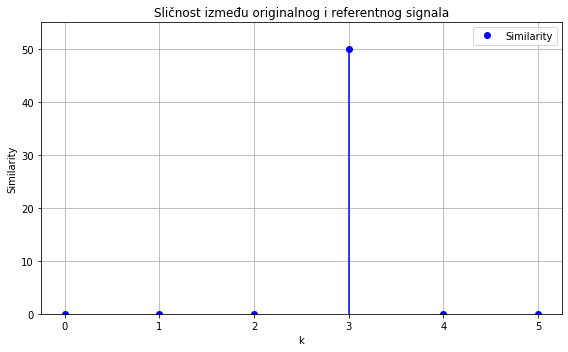

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def similarity(x, y):
    S = 0
    N = len(x)
    for n in range(N):
        S = S + x[n] * y[n]
    return S

N = 100 
fs = 50 
k_factors = [0, 1, 2, 3, 4, 5]  
n = np.arange(N) 

x = np.cos(2 * np.pi * 3/N * n) 

similarities = []

plt.figure(figsize=(12, 12))

for i, k in enumerate(k_factors):
    y = np.cos(2 * np.pi * k/N  * n)  
    S = similarity(x, y)    
    similarities.append(S)
    
    plt.subplot(6, 2, 2*i+1)
    plt.plot(n, x, label=f'ulazni', color='black', linewidth=2)
    plt.plot(n, y, label=f'referentni', linestyle='--')
    plt.title(f'Ulazni i referentni signal za k = {k}')
    plt.xlabel('Vrijeme (s)')
    plt.ylabel('Amplituda')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(6, 2, 2*i+2)
    product = x * y  
    plt.plot(n, product, color='green')
    plt.title(f'Umnožak po uzorcima za k = {k}')
    plt.xlabel('Vrijeme (s)')
    plt.ylabel('Amplituda')
    plt.grid(True)
    plt.ylim(-3, 3)  
    plt.subplots_adjust(top=1.1, hspace=0.5)

plt.figure(figsize=(8, 5))
plt.stem(k_factors, similarities, use_line_collection=True, basefmt=" ", linefmt='b-', markerfmt='bo', label="Similarity")
plt.title("Sličnost između originalnog i referentnog signala")
plt.xlabel('k')
plt.ylabel('Similarity')
plt.ylim(0, 55)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


### Sličnost sa sinusom

Dakle, kad signal $x[n]=\cos\left(2 \pi \cdot \frac{3}{N} \cdot n\right)$ usporedimo s referentnim signalom $y_3[n]=\cos\left(2 \pi \cdot \frac{3}{N} \cdot n\right)$, za taj $k$ dobit ćemo vrijednost $\frac{N}{2}$, a inače $0$. <br> Što se dogodi ako umjesto $x[n]=\cos(...)$ stavimo $x[n]=\sin(...)$? Ako pokrenemo ovaj primjer, pokazat će se da ćemo za sve frekvencije dobiti sličnost $=0$ iako imamo $k$ koji predstavlja identičnu frekvenciju. 

Nije teško i matematički pokazati da to i očekujemo. Znamo da je sinus zapravo kosinus pomaknut za $\frac{\pi}{2}$ $\left(\sin(\alpha)=\cos\left(\alpha-\frac{\pi}{2}\right)\right)$ pa u jedinom dijelu koji iz prethodnog izraza ostaje imamo sljedeće:
$$
\begin{equation}
S_3=\sum_{n=0}^{N-1}\frac{1}{2} \left[ \cos \left(2 \pi\cdot \frac{3-3}{N} \cdot n - \frac{\pi}{2}\right) \right]
\end{equation}
$$

$$
\begin{equation}
S_3=\sum_{n=0}^{N-1}\frac{1}{2} \cos\left(0-\frac{\pi}{2}\right) = 0
\end{equation}
$$

Općenito se za referentni signal kosinusa može pokazati:
$$
\begin{equation}
S_k (x, \cos)=\frac{N}{2} \cos(\Phi)
\end{equation}
$$
gdje je $\Phi$ početna faza signala $x[n]$.


S druge strane, ako referentni signal napišemo kao sinus, onda ćemo za novi $x[n]$, koji je u ovom slučaju sinusni signal s identičnom frekvencijom kao i jedan od referentnih signala, dobiti $S(x[n], \sin)=\frac{N}{2}$ (vrijedi $\sin(\alpha)\cdot\sin(\beta)=\frac{1}{2}\left[\cos(\alpha-\beta)-\cos(\alpha+\beta)\right]$) u točki $k=3$. 

Općenito za referentni signal sinusa možemo zapisati:
$$
\begin{equation}
S_k (x, \sin)=\frac{N}{2} \sin(\Phi)
\end{equation}
$$

***

Primijetimo da sličnost signala $x[n]$ ovisi o odabranoj referentnoj funkciji. Ako koristimo samo kosinus ili samo sinus, za određene početne faze $\Phi$ možemo dobiti rezultat jednak nuli, iako signal sadrži tu frekvenciju.

Zato signal $x[n]$ moramo usporediti **i s kosinusom i sa sinusom iste frekvencije**. 

Ako signal ima amplitudu $A$ i početnu fazu $\Phi$, vrijedi:

$$
\begin{equation}
S(x, \cos)=A\cdot\frac{N}{2}\cdot \cos(\Phi)
\end{equation}
$$

$$
\begin{equation}
S(x, \sin)=A\cdot\frac{N}{2}\cdot \sin(\Phi)
\end{equation}
$$

Te dvije vrijednosti zajedno daju potpunu informaciju o amplitudi i fazi signala na toj frekvenciji.

Zato ih možemo zapisati kao jedan kompleksan broj:

$$
\begin{equation}
X[k] = S(x,\cos) + j\,S(x,\sin)
\end{equation}
$$

gdje realni dio predstavlja sličnost s kosinusom, a imaginarni dio predstavlja sličnost sa sinusom. 

Upravo je to osnovna ideja **Diskretne Fourierove transformacije**:  
svaki referentni signal frekvencije $f_k=k\cdot \frac{f_s}{N}$ opisujemo pomoću dvije ortogonalne komponente (kosinusne i sinusne).

***

## Diskretna Fourierova transformacija


Za signal $x[n]$ s $N$ uzoraka, diskretna Fourierova transformacija (DFT) kreira $X[k]$ s $N$ kompleksnih brojeva koji predstavljaju amplitudu i fazu referentnih signala:


$$
\begin{equation}
X[k]=\sum_{n=0}^{N-1} x[n] \left[ \cos \left(2 \pi\cdot \frac{k}{N} \cdot n\right) - j\sin \left(2 \pi\cdot \frac{k}{N} \cdot n \right) \right]
\end{equation}
$$

To češće pišemo pomoću eksponencijalne funkcije:
$$
\begin{equation}
X[k]=\sum_{n=0}^{N-1} x[n] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}
\end{equation}
$$

***

DFT govori da se signal $x[n]$ može zapisati kao zbroj kompleksnih sinusoida. Koeficijent $X[k]$ predstavlja kompleksnu težinu frekvencijske komponente na frekvenciji $f_k$. Frekvencijska komponenta je sinusoidna oscilacija određene frekvencije koja sudjeluje u izgradnji signala. Svaka komponenta ima svoju amplitudu i fazu. Modul $|X[k]|$ određuje amplitudu komponente, dok kut $\angle X[k]$ određuje njezinu fazu. Drugim riječima, modul govori koliko je određena frekvencijska komponenta zastupljena u signalu, a kut predstavlja njezin fazni pomak.


Dakle, možemo zaključiti:

 1. $X[k]$ opisuje doprinos kompleksne sinusoide na frekvenciji $f_k$, gdje je $f_k=k\cdot \frac{f_s}{N}$
 2. Spektar $X$ ima $N$ spektralnih komponenti od kojih prvih $\frac{N}{2}$ predstavlja pozitivne frekvencije, a drugih $\frac{N}{2}$ negativne. 
 3. Modul $|X[k]|$ (u Pythonu np.abs($X[k]$)) odgovara amplitudi pripadne frekvencijske komponente, a kut $\angle X[k]$ (u Pythonu np.angle($X[k]$)) fazi.
 4. Graf modula $|X[k]|$ naziva se amplitudni (magnitudni) spektar signala $x[n]$, dok se graf kuta $\angle X[k]$ naziva fazni spektar.
 5. Ako je signal $x[n]$ realan, tada vrijedi Hermitska simetrija spektra:
   $X[N-k] = \overline{X[k]}$. 
   Iz toga slijedi da je amplitudni spektar $|X[k]|$ simetričan, dok je fazni spektar $\angle X[k]$ antisimetričan. To ćemo dodatno pojasniti kasnije u tekstu.
   
 
 

 

***

## Implementacija DFT-a


Diskretna Fourierova transformacija matematički rastavlja signal na njegove frekvencijske komponente. Kada je implementiramo izravno prema definiciji, za svaki frekvencijski bin $k$ prolazimo kroz sve uzorke signala $n$ i množimo svaki uzorak s kompleksnim eksponencijalom, odnosno s kosinusom i sinusom odgovarajuće frekvencije.

Upravo to radi funkcija `dft` u primjeru u nastavku. Vanjska petlja ide po frekvencijskim binovima $k$ od $0$ do $N-1$, unutarnja po uzorcima $n$, a svaki doprinos je $x[n]$ pomnožen s:

$$\cos\left(\frac{2\pi k n}{N}\right) - j\sin\left(\frac{2\pi k n}{N}\right)$$

Taj izraz je zapravo kompleksni eksponencijal rastavljen na realni i imaginarni dio:

$$X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j \frac{2\pi k n}{N}}$$



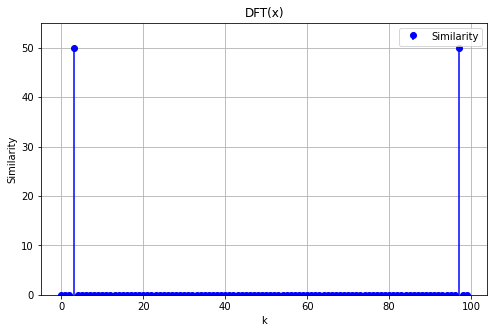

In [14]:


def dft(x):
    
    N = len(x)
    X = np.zeros(N, dtype=complex)
    
    for k in range(N):
        for n in range(N):
            X[k] = X[k] + x[n] * (np.cos(2 * np.pi * k / N * n) - 1j * np.sin(2 * np.pi * k / N * n))
    return X


plt.figure(figsize=(8, 5))
plt.stem(n, abs(dft(x)), use_line_collection=True, basefmt=" ", linefmt='b-', markerfmt='bo', label="Similarity")
plt.title("DFT(x)")
plt.xlabel('k')
plt.ylabel('Similarity')
plt.ylim(0, 55)
plt.grid(True)
plt.legend()


***

Rezultat za svaki $k$ je jedan kompleksni broj koji nam daje amplitudu i fazni pomak. Ova implementacija ima složenost $\mathcal{O}(N^2)$ jer za $N$ frekvencijskih binova radimo $N$ množenja, što za veće signale postaje izrazito sporo.



U praksi se zato koristi algoritam **Fast Fourier Transform** (FFT, Brza Fourierova transformacija). Algoritam se temelji na rekurzivnoj dekompoziciji. DFT veličine $N$ rastavlja se na dva DFT-a veličine $N/2$, a svaki od njih opet na dva od $N/4$, i tako dalje sve dok ne dođemo do trivijalne DFT veličine. Kasnije ćemo vidjeti kako točno radi FFT.
Za sad je važno da korištenjem FFT-a složenost pada s $\mathcal{O}(N^2)$ na $\mathcal{O}(N \log N)$, što za signal od $N = 1024$ uzoraka znači razliku između milijun i deset tisuća operacija.

***

U nastavku su najvažnije funkcije biblioteke *numpy* koje koristimo za implementaciju diskretne Fourierove transformacije:

 - `np.fft.fft`

  - Vraća kompleksni niz duljine $N$ koji predstavlja DFT ulaznog signala. Binovi su posloženi tako da prva polovica niza odgovara pozitivnim frekvencijama od $0$ do $f_s/2$, a druga polovica negativnim frekvencijama od $-f_s/2$ prema $0$. Taj raspored potječe izravno iz matematičke definicije, ali nije intuitivan za prikaz.

 -  `np.fft.fftfreq`

  - Generira os frekvencija koja odgovara binovima koje `fft` vraća. Odnosno, ne prikazuje više po parametru $k$, već po frekvencijama $f_k$. Prima dva argumenta: broj uzoraka ($N$) i frekvenciju uzorkovanja ($f_s$) kako bi mogao mapirati iz $k$ u $f_k$ prema 
$f_k=k\cdot \frac{f_s}{N} \text{ [Hz]}$


 -  `np.fft.fftshift`

  - Preraspoređuje izlaz `fft`-a tako da nulta frekvencija dođe u sredinu niza, a frekvencije rastu s lijeva na desno od negativnih prema pozitivnima. Bez ovog koraka graf spektra bio bi "prelomljen" i teško čitljiv. Kada se kroz `fftshift` propusti i frekvencijska os, dobivamo simetričan dvostruki spektar centriran oko $f = 0$.

 -  `np.abs`

  - Računa modul svakog kompleksnog broja u spektru:
$$|X[k]| = \sqrt{\text{Re}(X[k])^2 + \text{Im}(X[k])^2}$$

  - To je **amplitudni spektar** koji pokazuje snagu svake frekvencijske komponente bez obzira na fazu. Za realni kosinus očekujemo dva vrha simetrična oko nule, svaki s amplitudom $N/2$.

 -  `np.angle`

  - Vraća kut kompleksnog broja $X[k]$, odnosno kut koji taj broj zatvara s pozitivnom realnom osi u kompleksnoj ravnini. To je **fazni spektar** koji za svaku frekvencijsku komponentu opisuje njezin fazni pomak u signalu.



Napomena: Implementirana funkcija `phase_masked`

Numeričke operacije s plutajućim zarezom nikada nisu savršeno precizne. Binovi u kojima nema stvarnog signala ne daju točno nulu, nego iznimno male vrijednosti poput $10^{-15}$, koje su isključivo plod numeričkih pogrešaka. Funkcija `np.angle` primijenjena na takav gotovo-nulti kompleksni broj vratit će nasumičan kut između $-\pi$ i $\pi$, jer i najmanji numerički šum određuje smjer vektora koji je praktički nulte duljine. Rezultat bi bio fazni spektar pun šuma u svim binovima.

`phase_masked` rješava to maskiranjem:

```python
phase_masked = np.where(mag > threshold, phase, np.nan)
```

Svuda gdje je magnituda ispod praga (*threshold*) $10^{-10}$ faza se zamjenjuje s `nan`, a Matplotlib `nan` vrijednosti jednostavno ne crta. Na taj način fazni spektar prikazuje fazu samo tamo gdje postoji smislena amplituda.

***

U sljedećem primjeru signal je kosinus pa očekujemo:

$$\angle X[k] = 0 \quad \text{na } f = \pm 1.5 \text{ Hz}$$

Kad dodamo fazni pomak $\varphi = \pi/4$:

$$x[n] = \cos\left(2\pi \cdot 1.5 \cdot \frac{n}{f_s} + \frac{\pi}{4}\right)$$

fazni spektar pokaže $+\pi/4$ na pozitivnoj frekvenciji i $-\pi/4$ na negativnoj, što je simetrija koja vrijedi za sve realne signale.

<IPython.core.display.Javascript object>


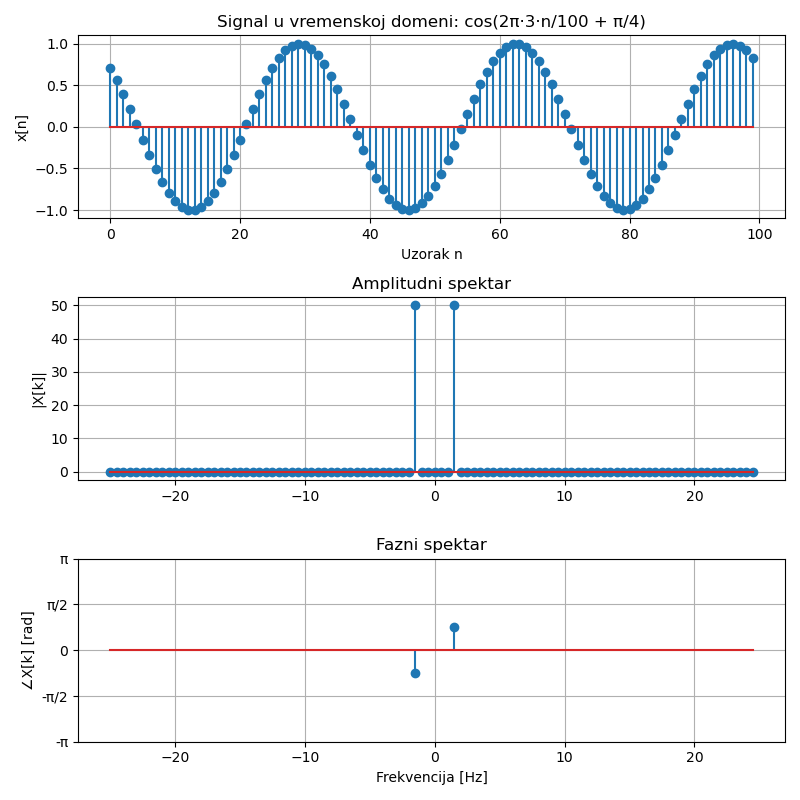

In [6]:
%matplotlib notebook
import numpy as np
import matplotlib.pyplot as plt

N = 100 
fs = 50 
n = np.arange(N) 

k0 = 3
fk= k0 * fs/N   #fk=1.5 Hz

x = np.cos(2 * np.pi * fk * n/fs + np.pi/4) #  

X = np.fft.fftshift(np.fft.fft(x))
freqs = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))

mag = np.abs(X)
phase = np.angle(X)

# Fazni spektar - prikaži samo gdje je magnituda značajna
threshold = 1e-10
phase_masked = np.where(mag > threshold, phase, np.nan)

fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(8, 8))

ax0.stem(n, x)
ax0.set_ylabel("x[n]")
ax0.set_xlabel("Uzorak n")
ax0.set_title("Signal u vremenskoj domeni: cos(2π·3·n/100 + π/4)")
ax0.grid(True)

ax1.stem(freqs, mag)
ax1.set_ylabel("|X[k]|")
ax1.set_title("Amplitudni spektar")
ax1.grid(True)

ax2.stem(freqs, phase_masked)
ax2.set_ylabel("∠X[k] [rad]")
ax2.set_xlabel("Frekvencija [Hz]")
ax2.set_title("Fazni spektar")
ax2.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax2.set_yticklabels(['-π', '-π/2', '0', 'π/2', 'π'])
ax2.grid(True)

plt.tight_layout()
plt.show()

***

## DFT impulsa

Pogledajmo nekoliko primjera u frekvencijskoj domeni. Što ako je $x[n]=\delta[n]$? 

DFT tada računamo:

$$
\begin{equation}
X[k]=\sum_{n=0}^{N-1} \delta[n] e^{-j 2 \pi\cdot \frac{k}{N} \cdot n}
\end{equation}
$$

Budući da  $\delta[n]$ ima vrijednost $\ne 0$ samo za $n=0$, pišemo
$$
\begin{equation}
X[k]=1\cdot e^0
\end{equation}
$$

Dakle, za svaki $k$ u $X[k]$ kao rezultat dobivamo kompleksni broj $1+0j$. Realni dio je $1$, a imaginarni $0$. Kad pogledamo što to zapravo znači, vidjet ćemo da ima smisla. Realni i imaginarni dio proizlaze iz kosinusne i sinusne komponente kompleksne eksponencijale. U trenutku $n=0$ vrijedi $\cos(0) = 1$ i $\sin(0) = 0$ pa je realni dio jednak $1$, a imaginarni $0$. To možemo interpretirati ovako: jedinični impuls u vremenskoj domeni sadrži sve frekvencijske komponente s jednakom amplitudom (vrijednosti $1$) i bez pomaka u fazi.

***


Što će se dogoditi ako impuls pomaknemo u vremenu za $d$?

$$X[k]=\sum_{n=0}^{N-1} \delta[n-d]\, e^{-j 2 \pi \frac{k}{N} n}$$

Budući da je $\delta[n-d]$ različit od nule samo u trenutku $n=d$, cijela suma se svede na jedan jedini član:

$$X[k] = e^{-j 2 \pi \frac{k}{N} d}$$

Amplituda ostaje jednaka $1$ za svaki $k$, ali faza više nije nula. Ako ovo raspišemo po Eulerovom identitetu, vidimo da realni i imaginarni dio spektra tvore sinusoide po frekvencijskoj osi $k$:

$$\text{Re}(X[k]) = \cos\!\left(2\pi \frac{d}{N} k\right), \qquad \text{Im}(X[k]) = -\sin\!\left(2\pi \frac{d}{N} k\right)$$

Intuitivno, razlog je isti kao i kod nepomaknute delta funkcije. Sve referentne sinusoide moraju prolaziti kroz vrijednost impulsa samo što je sada taj trenutak pomaknut na $n=d$. Svaka frekvencijska komponenta mora biti fazno zarotirana upravo toliko da i dalje prođe kroz impuls u pravom trenutku. Budući da fazni pomak raste linearno s $k$, u frekvencijskoj domeni dobivamo sinusoidalne promjene realnog i imaginarnog dijela.
Drugim riječima, i dalje su prisutne sve frekvencije kao i u prvom slučaju, ali sada svaka od njih ima drugačiji fazni pomak. Upravo ta linearna ovisnost faze o $k$ rezultira sinusoidama koje predstavljaju realni i imaginarni dio $X[k]$.

Pogledajmo sada u drugom smjeru. Ako uzmemo samo realni dio $X[k]$, dakle kosinus frekvencije $d/N$ po osi $k$, i na njemu primijenimo FFT, dobit ćemo dva impulsa na frekvencijskim binovima $\pm d$. A to je zapravo spektar kosinusa.

***

Pogledajmo sada u drugom smjeru. Realni dio $X[k] = \cos\!\left(2\pi \frac{d}{N} k\right)$ 
jest kosinusna funkcija po frekvencijskoj osi $k$ koja napravi točno $d$ punih perioda 
preko $N$ binova (za $d=2$ vidimo dva perioda, za $d=3$ tri, i tako dalje). 
Taj signal možemo promatrati kao diskretnu sinusoidu definiranu nad indeksom $k$.

Ako sada na taj signal primijenimo DFT (po varijabli $k$), dobivamo novi niz koji možemo interpretirati u domeni $n$. Poznato je da DFT diskretne sinusoide daje spektar s dva simetrična impulsa na pozicijama $n = \pm d$.
Sinusoida u jednoj domeni odgovara diskretnim impulsima u drugoj domeni. U našem slučaju, impuls pomaknut u vremenu za $d$ uzrokuje linearnu fazu u frekvenciji, čiji realni dio (i imaginarni) ima sinusoidni oblik, a DFT te sinusoide ponovno daje impulse na pozicijama $\pm d$.


Sve to pokazano je na sljedećem primjeru.


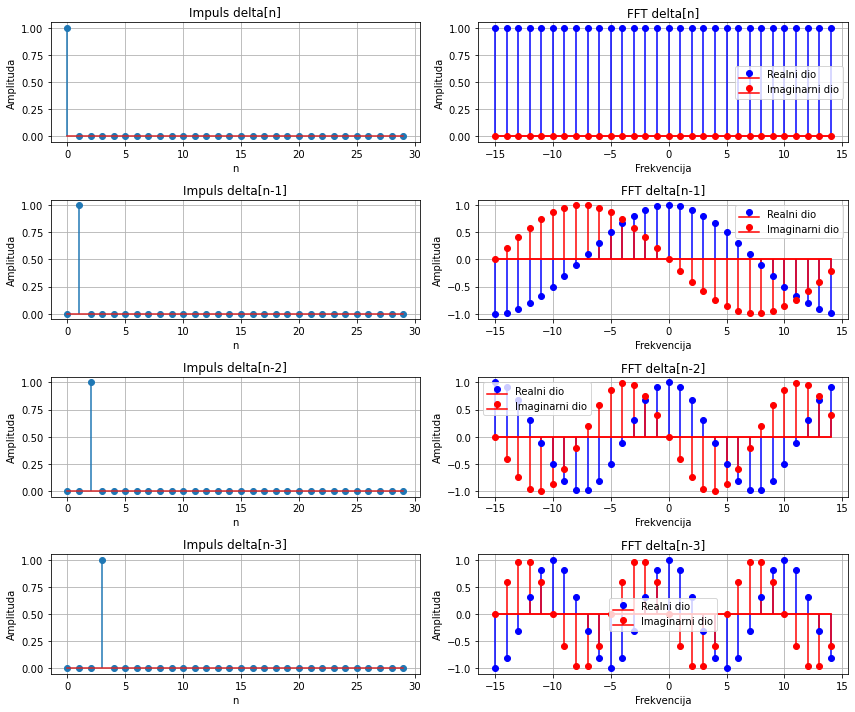

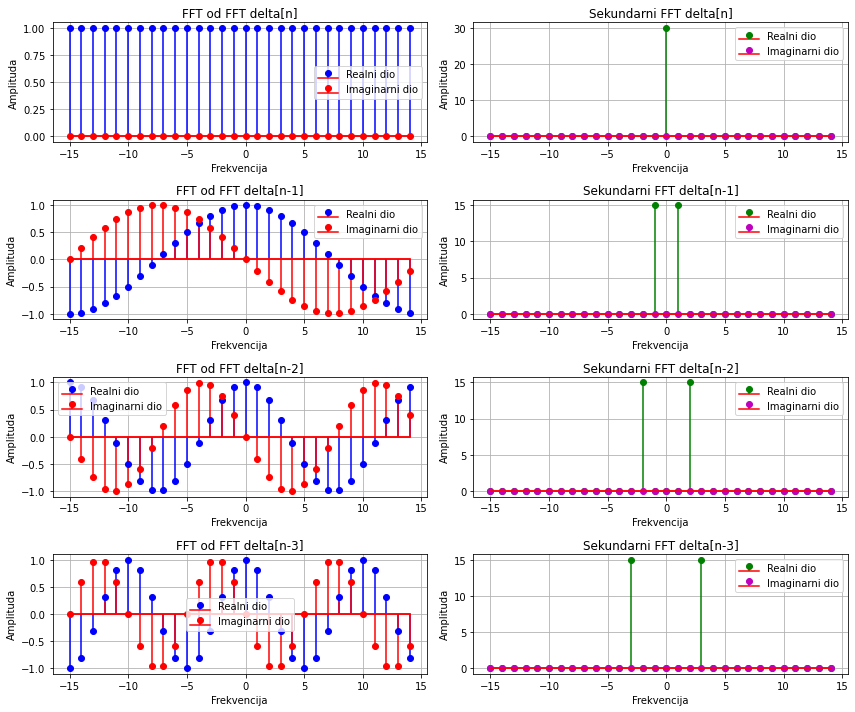

In [134]:
import numpy as np
import matplotlib.pyplot as plt

# Broj uzoraka
N = 30

impulses = {
    "delta[n]": np.array([1 if n == 0 else 0 for n in range(N)]),
    "delta[n-1]": np.array([1 if n == 1 else 0 for n in range(N)]),
    "delta[n-2]": np.array([1 if n == 2 else 0 for n in range(N)]),
    "delta[n-3]": np.array([1 if n == 3 else 0 for n in range(N)])
}

# Frekvencijska os
freqs = np.fft.fftfreq(N, 1/N)

plt.figure(figsize=(12, 10))

fft_results = {}

for i, (name, impulse) in enumerate(impulses.items()):
    X = np.fft.fft(impulse)
    fft_results[name] = X  
    
    plt.subplot(4, 2, 2*i + 1)
    plt.stem(range(N), impulse, use_line_collection=True)
    plt.xlabel('n')
    plt.ylabel('Amplituda')
    plt.title(f'Impuls {name}')
    plt.grid()
    
    plt.subplot(4, 2, 2*i + 2)
    plt.stem(freqs, X.real, markerfmt='bo', linefmt='b-', basefmt='r-', label='Realni dio', use_line_collection=True)
    plt.stem(freqs, X.imag, markerfmt='ro', linefmt='r-', basefmt='r-', label='Imaginarni dio', use_line_collection=True)
    plt.xlabel('Frekvencija')
    plt.ylabel('Amplituda')
    plt.title(f'FFT {name}')
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))

for i, (name, fft_result) in enumerate(fft_results.items()):
    # FFT na dobivenim FFT rezultatima
    X_fft = np.fft.fft(fft_result.real)
    
    plt.subplot(4, 2, 2*i + 1)
    plt.stem(freqs, fft_result.real, markerfmt='bo', linefmt='b-', basefmt='r-', label='Realni dio', use_line_collection=True)
    plt.stem(freqs, fft_result.imag, markerfmt='ro', linefmt='r-', basefmt='r-', label='Imaginarni dio', use_line_collection=True)
    plt.xlabel('Frekvencija')
    plt.ylabel('Amplituda')
    plt.title(f'FFT od FFT {name}')
    plt.legend()
    plt.grid()
    
    plt.subplot(4, 2, 2*i + 2)
    plt.stem(freqs, X_fft.real, markerfmt='go', linefmt='g-', basefmt='r-', label='Realni dio', use_line_collection=True)
    plt.stem(freqs, X_fft.imag, markerfmt='mo', linefmt='m-', basefmt='r-', label='Imaginarni dio', use_line_collection=True)
    plt.xlabel('Frekvencija')
    plt.ylabel('Amplituda')
    plt.title(f'Sekundarni FFT {name}')
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()